# Анализ Netflix Movies and TV Shows
Датасет: https://www.kaggle.com/datasets/shivamb/netflix-shows

**Структура ноутбука**
1. Знакомство
2. Очистка
3. Анализ
4. Вывод

In [4]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# для них и нужен ауторелоад
import analysis
import cleaning

# best standart design
plt.rcParams["figure.figsize"] = (9, 5) # размер отображаемой области графика: 9 на 5 дюймов
plt.rcParams["axes.grid"] = True # сеточка чтобы комфортно смотреть на графики
plt.rcParams["grid.alpha"] = 0.3 # слабо заметная сеточка 30% прозрачности
pd.set_option("display.max_columns", 20) # на всякий случай 20 столбцов наш предел

MIN_TITLES = 20  # годы, где тайтлов меньше, на графиках долей не показываем: там слишком мало данных
MONTHS_RU = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Знакомство с данными

In [5]:
raw = cleaning.load_data("data/netflix_titles.csv")
print(f"Строк: {raw.shape[0]}, столбцов: {raw.shape[1]}")
raw.head()

Строк: 8807, столбцов: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [7]:
# проверяем подозрения
dates = raw["date_added"].dropna() # убираем пропуски (наны) чтобы следующие принты были корректны
print("дат с пробелом в начале:", dates.str.startswith(" ").sum(), "из", len(dates))
print("duration — это строка, а не число:", raw["duration"].dropna().head(3).tolist()) 

дат с пробелом в начале: 88 из 8797
duration — это строка, а не число: ['90 min', '2 Seasons', '1 Season']


In [24]:
# у нескольких строк длительность попала в столбец rating
raw[raw["rating"].str.contains("min", na=False)][["title", "type", "rating", "duration"]]

,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


> **это никуда не годится - много черновых данных - надо фиксить (см. cleaning)**

## 2. Очистка

### 2.1 Пропуски

In [9]:
missing_table = pd.DataFrame({
    "пропусков, шт": raw.isna().sum(),
    "пропусков, %": cleaning.missing_share(raw).round(2),
}).sort_values("пропусков, %", ascending=False)
missing_table

,"пропусков, шт","пропусков, %"
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
description,0,0.00
listed_in,0,0.00
release_year,0,0.00
show_id,0,0.00


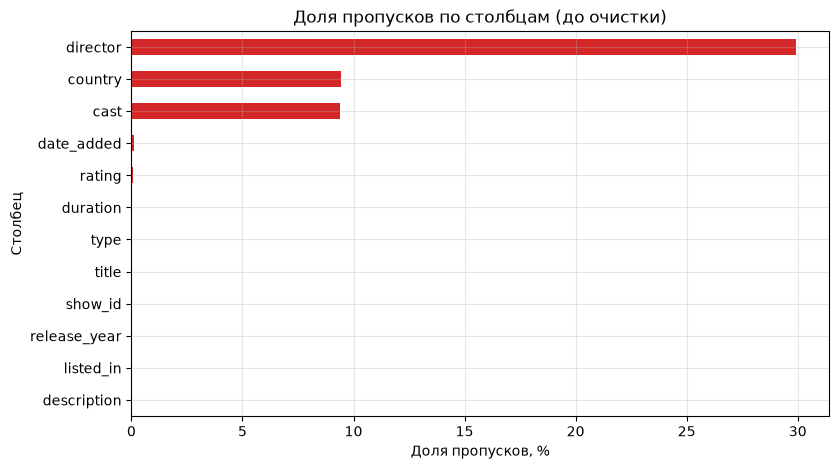

In [10]:
#берем из missing_table столбец с процентом пропусков, сортируем и строим горизонтальную (barh=bar-horizont) диаграмму
missing_table["пропусков, %"].sort_values().plot.barh(color="tab:red")
plt.title("Доля пропусков по столбцам (до очистки)")
plt.xlabel("Доля пропусков, %")
plt.ylabel("Столбец")
plt.show()

**Предложение**

| Столбец | Решение |
|---|---|
| `director` | заполняем `"Unknown"` |
| `cast` | заполняем `"Unknown"` |
| `country` | заполняем `"Unknown"` |
| `date_added` | не заполняем, остаётся `NaT` |
| `rating` | сначала клиним, потом `"Unknown"` |
| `duration` | клиним |

### 2.2 Дубликаты

In [27]:
dups = pd.Series({
    "полные дубликаты строк": raw.duplicated().sum(),
    "дубликаты по show_id": raw["show_id"].duplicated().sum(),
    "дубликаты по (title, type, release_year)": raw.duplicated(subset=["title", "type", "release_year"]).sum(),
}, name="количество")
dups.to_frame()

,количество
полные дубликаты строк,0
дубликаты по show_id,0
"дубликаты по (title, type, release_year)",0


> **дубликатов не найдено** - хотя в задании как будто подразумевались

### 2.3 Применяем очистку

In [11]:
df = cleaning.clean(raw)
print("размер до очищения:", raw.shape, "-> после:", df.shape)
df[["date_added", "duration", "duration_min", "seasons", "year_added", "years_to_netflix", "n_genres", "n_countries"]].head()

размер до очищения: (8807, 12) -> после: (8807, 19)


,date_added,duration,duration_min,seasons,year_added,years_to_netflix,n_genres,n_countries
0,2021-09-25,90 min,90.0,NaN,2021,1,1,1.0
1,2021-09-24,2 Seasons,NaN,2.0,2021,0,3,1.0
2,2021-09-24,1 Season,NaN,1.0,2021,0,3,NaN
3,2021-09-24,1 Season,NaN,1.0,2021,0,2,NaN
4,2021-09-24,2 Seasons,NaN,2.0,2021,0,3,1.0


## 3. Анализ

### 3.1 Распределения числовых признаков и выбросы

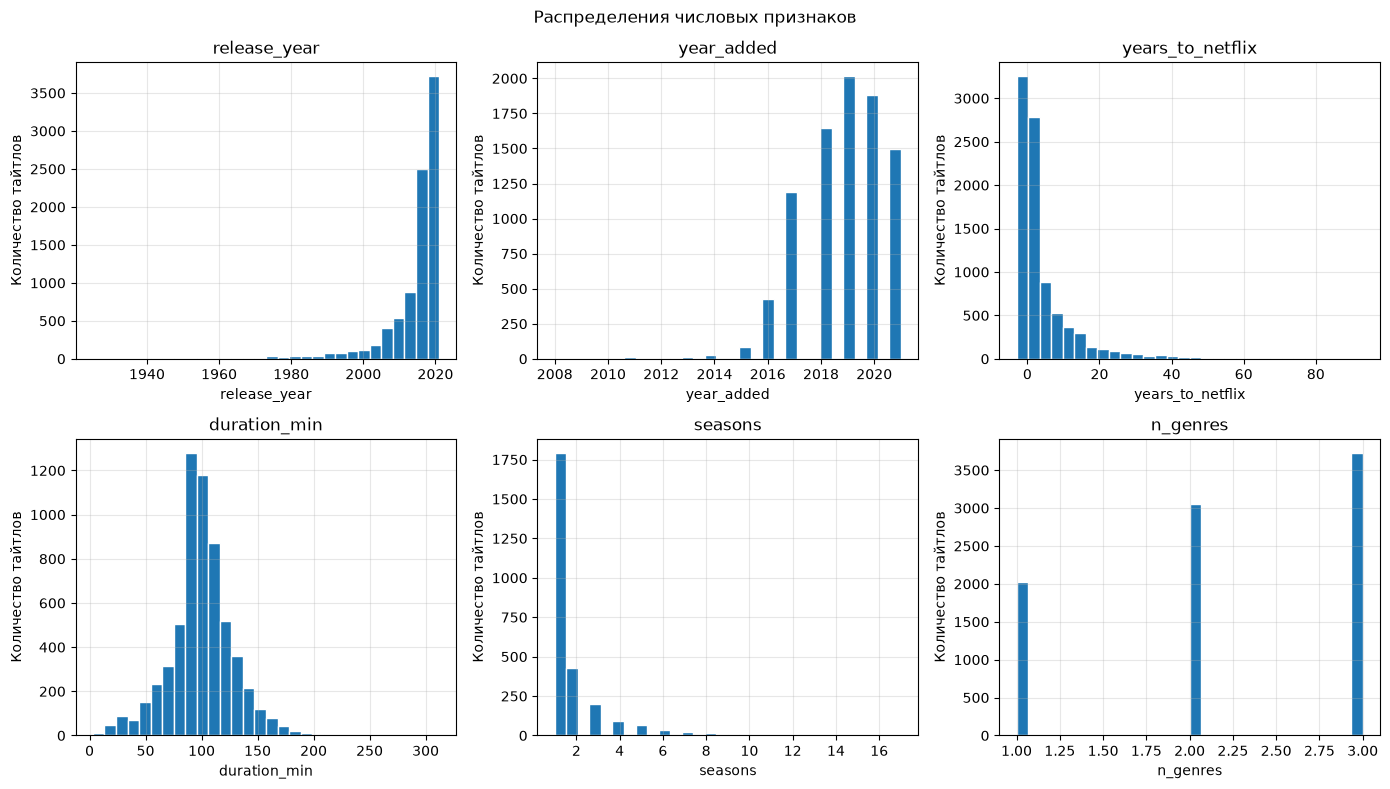

In [17]:
# исследуемые столбцы
num_cols = ["release_year", "year_added", "years_to_netflix", "duration_min", "seasons", "n_genres"]

# axes - массив 6 графиков, в plt отображаемая область графика называются 'ax'; canv - холст на котором размещены эти графики
canv, axes = plt.subplots(2, 3, figsize=(14, 8)) # два графика на вертикали, три на горизонатали, каждый 14x8

for ax, col in zip(axes.ravel(), num_cols): # ravel делает из 2*3 - 6*1; чтобы зип корректно сопоставил названия графикам
    ax.hist(
        df[col].dropna().astype(float), 
        bins=30, # диапазон значений на 30 под'интервалов
        color="tab:blue", 
        edgecolor="white"
    )
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Количество тайтлов")

canv.suptitle("Распределения числовых признаков")
canv.tight_layout() # красиво группирует чтобы ничего друг на друга не накладывалось
plt.show()

In [18]:
num_data = df[num_cols].astype(float)
stats = num_data.describe().round(2)
stats

,release_year,year_added,years_to_netflix,duration_min,seasons,n_genres
count,8807.00,8797.00,8797.00,6131.00,2676.00,8807.00
mean,2014.18,2018.87,4.69,99.56,1.76,2.19
std,8.82,1.57,8.79,28.29,1.58,0.78
min,1925.00,2008.00,-3.00,3.00,1.00,1.00
25%,2013.00,2018.00,0.00,87.00,1.00,2.00
50%,2017.00,2019.00,1.00,98.00,1.00,2.00
75%,2019.00,2020.00,5.00,114.00,2.00,3.00
max,2021.00,2021.00,93.00,312.00,17.00,3.00


In [15]:
# выбросы по правилу IQR
rows = []
for col in ["duration_min", "seasons"]:
    values = df[col].astype(float)
    outliers, low, high = analysis.iqr_outliers(values)
    rows.append({
        "признак": col,
        "нижняя граница": low,
        "верхняя граница": high,
        "выбросов, шт": len(outliers),
        "выбросов, %": len(outliers) / values.notna().sum() * 100,
    })
iqr_table = pd.DataFrame(rows).round(2)
iqr_table

,признак,нижняя граница,верхняя граница,"выбросов, шт","выбросов, %"
0,duration_min,46.5,154.5,450,7.34
1,seasons,-0.5,3.5,259,9.68


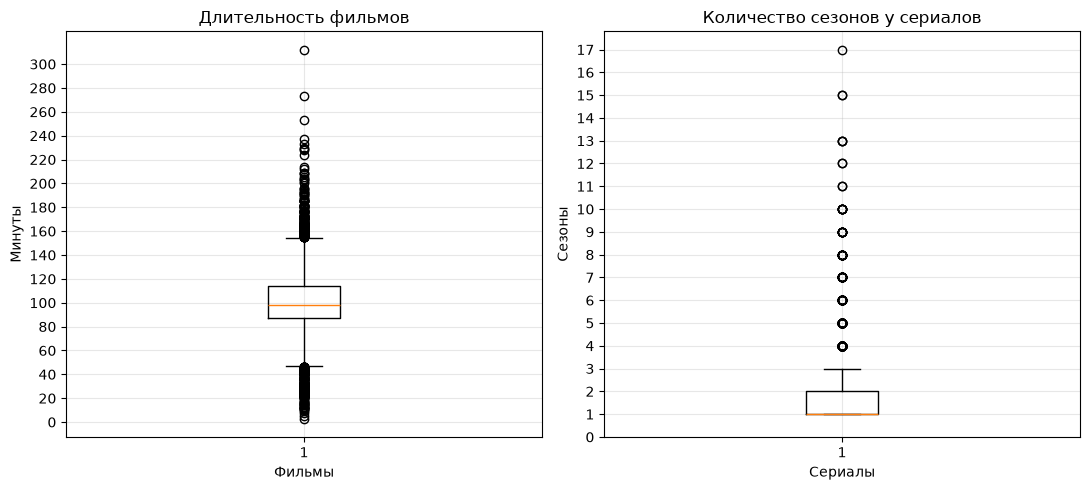

Самые длинные фильмы:


,title,release_year,duration_min
4253,Black Mirror: Bandersnatch,2018,312.0
717,Headspace: Unwind Your Mind,2021,273.0
2491,The School of Mischief,1973,253.0
2487,No Longer kids,1979,237.0
2484,Lock Your Girls In,1982,233.0


Сериалы с наибольшим числом сезонов:


,title,release_year,seasons
548,Grey's Anatomy,2020,17.0
2423,Supernatural,2019,15.0
4798,NCIS,2017,15.0
1354,Heartland,2019,13.0
4220,COMEDIANS of the world,2019,13.0


In [34]:
# в прошлый раз использовал canv как название холста, но в plt принято скорее fig как стандартное обозначение
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# ящик с усами для первого графика (т.е. для фильмов)
axes[0].boxplot(df["duration_min"].dropna())
axes[0].set_title("Длительность фильмов")
axes[0].set_xlabel("Фильмы")
axes[0].set_ylabel("Минуты")
axes[0].set_yticks(range(0, 301, 20))

# ящик с усами для второго графика (т.е. для сериалов)
axes[1].boxplot(df["seasons"].dropna())
axes[1].set_title("Количество сезонов у сериалов")
axes[1].set_xlabel("Сериалы")
axes[1].set_ylabel("Сезоны")
axes[1].set_yticks(range(0, 18, 1))

fig.tight_layout()
plt.show()

# dispay поэстетичнее print будет для df
print("Самые длинные фильмы:")
display(df.nlargest(5, "duration_min")[["title", "release_year", "duration_min"]])
print("Сериалы с наибольшим числом сезонов:")
display(df.nlargest(5, "seasons")[["title", "release_year", "seasons"]])

> Фильмы в основном по 87–114 минут. Всё что короче 46 и длиннее 154 минут считается аномалией(выбросом), таких 7%: это не ошибки, а спецвыпуски или очень длинные фильмы. У большинства сериалов 1 сезон, а 4+ сезона только у 9.7%.

### 3.2 Корреляции

In [35]:
# столбцы, между которыми хотим проверить связь
corr_cols = ["release_year", "year_added", "years_to_netflix", "duration_min", "n_genres", "n_countries"]

# np.corrcoef не умеет работать с пропусками (nan), поэтому убираем
corr_data = df[corr_cols].dropna().to_numpy(dtype=float)
print("строк для наблюдения корреляции:", corr_data.shape[0])

corr = np.corrcoef(corr_data, rowvar=False) # характиристики (т.e. year, min..) находятся в столбцах - поэтому rowvar=false
pd.DataFrame(corr, index=corr_cols, columns=corr_cols).round(2)

Строк в корреляции: 5691


,release_year,year_added,years_to_netflix,duration_min,n_genres,n_countries
release_year,1.00,0.02,-0.99,-0.20,-0.09,-0.00
year_added,0.02,1.00,0.14,0.14,0.09,0.01
years_to_netflix,-0.99,0.14,1.00,0.22,0.10,0.00
duration_min,-0.20,0.14,0.22,1.00,0.40,0.04
n_genres,-0.09,0.09,0.10,0.40,1.00,0.01
n_countries,-0.00,0.01,0.00,0.04,0.01,1.00


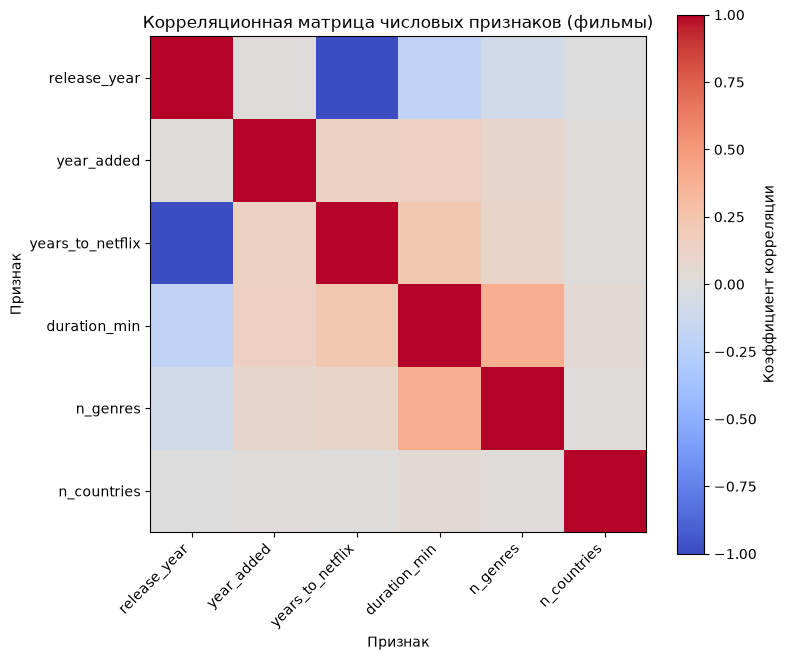

In [40]:
fig, ax = plt.subplots(figsize=(8, 7))

#рисуем тепловую карту
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)

fig.colorbar(im, ax=ax, label="Коэффициент корреляции") # справа шкала, поясняющая цвет числом

ax.set_title("Корреляционная матрица числовых признаков (фильмы)")
ax.set_xlabel("Признак")
ax.set_ylabel("Признак")
ax.grid(False)

plt.show()

> Самая сильная пара — `release_year` и `years_to_netflix` (−0.99), но это тривиально: `years_to_netflix = year_added − release_year`. Из содержательных связей: чем больше у фильма жанров, тем он обычно длиннее (0.40). Новые фильмы чуть короче старых (−0.20). Количество стран ни с чем не связано. Считали только по фильмам (в силу duration_min).

### 3.3 Вопрос 1. Правда ли, что Netflix в основном добавляет старый контент?
Считаем `years_to_netflix = год добавления − год выхода`.

In [99]:
gap = df["years_to_netflix"].dropna().astype(int)
print("добавлено раньше выхода:", (gap < 0).sum())
gap = gap[gap >= 0]  # отрицательные — некорректно внесенные данные, убираем из анализа

gap_stats = gap.describe().round(2).to_frame("years_to_netflix")
gap_stats.loc["median"] = gap.median()
gap_stats

добавлено раньше выхода: 14


,years_to_netflix
count,8783.00
mean,4.70
std,8.79
min,0.00
25%,0.00
50%,1.00
75%,5.00
max,93.00
median,1.00


In [46]:
gap_np = gap.to_numpy() # чтобы применить select
category = np.select(
    [gap_np <= 2, gap_np <= 10], # условия
    ["свежий (0–2 года)", "средний (3–10 лет)"], # метки
    default="старый (больше 10 лет)",
)

age_share = (
    pd.Series(category) # обратно из np в pd
    .value_counts(normalize=True) # из обычного каунтера normalize=1 делает дольный каунтер
    .mul(100) # множим на 100 чтобы увидеть проценты
    .round(1)
)
age_share.to_frame("доля тайтлов, %")

,"доля тайтлов, %"
свежий (0–2 года),63.1
средний (3–10 лет),23.2
старый (больше 10 лет),13.7


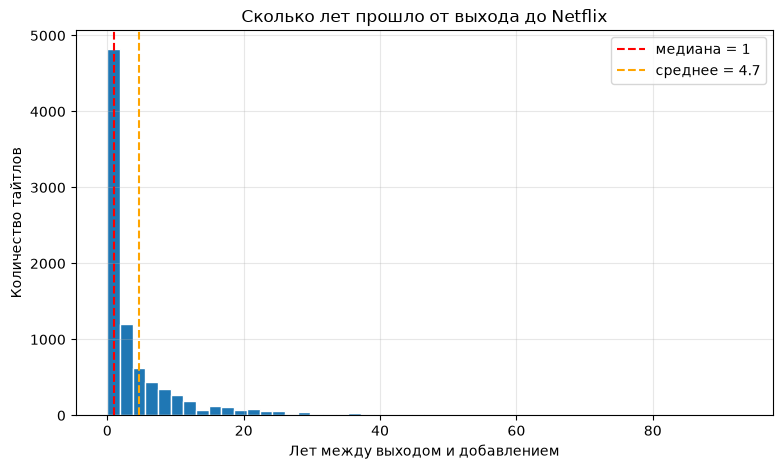

In [49]:
plt.figure(figsize=(9, 5))
plt.hist(gap, bins=50, color="tab:blue", edgecolor="white")

plt.axvline(# рисует вертикальную красную линию
    gap.median(), # координата по оси x - медианнное значение
    color="red", 
    linestyle="--", 
    label=f"медиана = {gap.median():.0f}"
)

plt.axvline(
    gap.mean(), # координата по оси x - среднее значение
    color="orange", 
    linestyle="--", 
    label=f"среднее = {gap.mean():.1f}"
)

plt.title("Сколько лет прошло от выхода до Netflix")
plt.xlabel("Лет между выходом и добавлением")
plt.ylabel("Количество тайтлов")
plt.legend()
plt.show()

In [101]:
print(f"разница старше 10 лет: {(gap > 10).mean() * 100:.1f}%")

разница старше 10 лет: 13.7%


In [51]:
gap_by_type = (
    df.groupby("type")["years_to_netflix"]
    .agg(["median", "mean"])
    .round(2)
)

display(gap_by_type)

,median,mean
type,,
Movie,2.0,5.73
TV Show,0.0,2.3


> Netflix добавляет в основном новое. Обычно проходит всего 1 год между выходом и появлением на Netflix, а старше 10 лет почти 14% тайтлов. Есть несколько очень старых фильмов, поэтому смотрим на медиану. 14 строк (добавлено раньше выхода) не учитывали.

### 3.4 Вопрос 2. Как менялось соотношение фильмов и сериалов по годам добавления?

In [52]:
by_year = df.pivot_table( # сводная комфортная таблица
    index="year_added", 
    columns="type", 
    values="show_id",
    aggfunc="count", # считаем колво сериалов и фильмов
    fill_value=0 # наны меняем на 0
)
by_year["Всего"] = by_year[["Movie", "TV Show"]].sum(axis=1)
by_year["Доля фильмов, %"] = (by_year["Movie"] / by_year["Всего"] * 100).round(1)
by_year

type,Movie,TV Show,Всего,"Доля фильмов, %"
year_added,,,,
2008,1,1,2,50.0
2009,2,0,2,100.0
2010,1,0,1,100.0
2011,13,0,13,100.0
2012,3,0,3,100.0
2013,6,5,11,54.5
2014,19,5,24,79.2
2015,56,26,82,68.3
2016,253,176,429,59.0


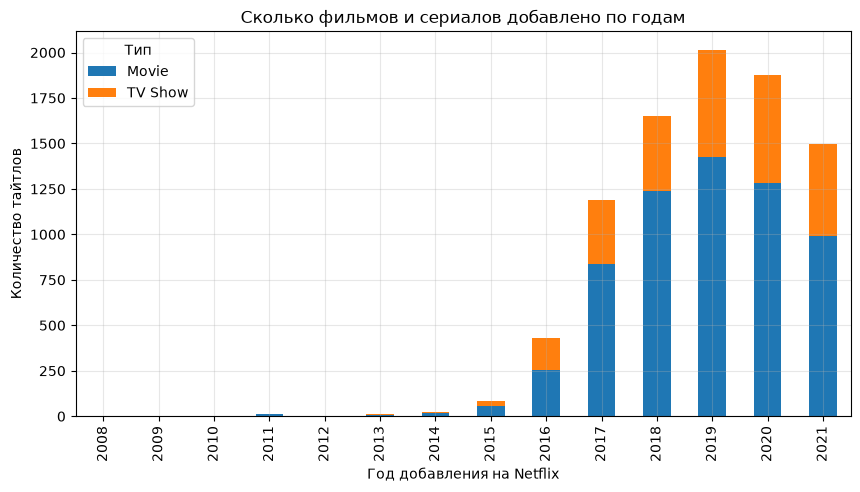

In [55]:
by_year[["Movie", "TV Show"]].plot(
    kind="bar", # столбчатая диаграмма 
    stacked=True, # сериалы приклеиваем сверху к фильмам
    figsize=(10, 5),
    color=["tab:blue", "tab:orange"]
)
plt.title("Сколько фильмов и сериалов добавлено по годам")
plt.xlabel("Год добавления на Netflix")
plt.ylabel("Количество тайтлов")
plt.legend(title="Тип")
plt.show()

> Netflix стал добавлять намного больше контента: менее ста в 2015, около пятисот в 2016, пик в 2019, потом чуть меньше. Фильмов всегда больше, примерно две трети. Сериалы: меньше всего в 2018, к 2021 доля снова выросла. До 2014 года контента слишком мало, выводов по ним не делаем.

### 3.5 Вопрос 3. Становятся ли фильмы длиннее с годами выпуска?

In [57]:
movies = df[df["type"] == "Movie"].dropna(subset=["duration_min"])
print("фильмов с известной длительностью:", len(movies))

by_release = movies.groupby("release_year")["duration_min"].agg(
    ["median", "mean", "count"]
)
by_release = by_release[by_release["count"] >= MIN_TITLES]  # только годы с достаточным числом фильмов
by_release.round(1).tail(10)

фильмов с известной длительностью: 6131


,median,mean,count
release_year,,,
2012,98.0,100.8,173
2013,99.0,98.0,225
2014,100.5,100.3,264
2015,97.0,99.4,398
2016,95.0,95.4,658
2017,94.0,95.5,767
2018,96.0,96.2,767
2019,95.0,93.5,633
2020,96.0,92.1,517


годы в тренде: 1992–2021
тренд медианной длительности: -0.64 мин за год


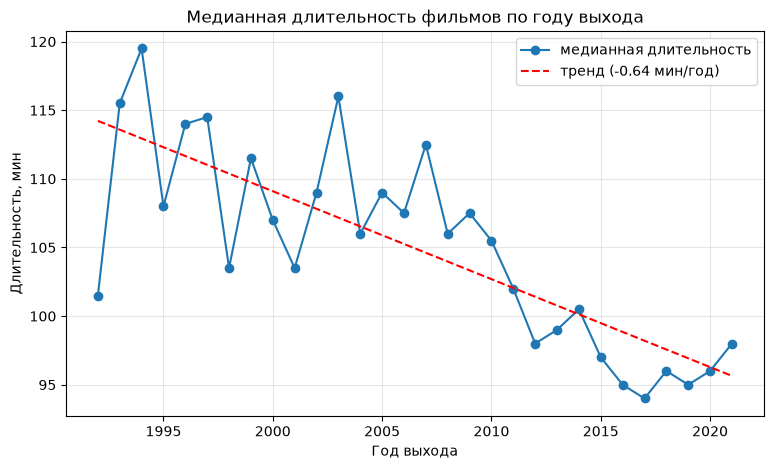

In [64]:
# линия тренда через np.polyfit (степень 1 = прямая)
x = by_release.index.to_numpy(dtype=float) # годы выхода фильмов
y = by_release["median"].to_numpy(dtype=float) # медианная длительность фильмов
slope, intercept = np.polyfit(x, y, 1) # любопытно: формула y = slope * x + intercept (уравнение прямой y = kx + m)

print(f"годы в тренде: {int(x.min())}–{int(x.max())}")
print(f"тренд медианной длительности: {slope:.2f} мин за год")

plt.plot(x, y, marker="o", label="медианная длительность")
# строим красную прямую тренда
plt.plot(x, slope * x + intercept, "r--", label=f"тренд ({slope:.2f} мин/год)")

plt.title("Медианная длительность фильмов по году выхода")
plt.xlabel("Год выхода")
plt.ylabel("Длительность, мин")
plt.legend()
plt.show()

> Фильмы становятся короче примерно на 6 минут за 10 лет. В 1990-х типичный фильм шёл около 100–120 минут, в последние годы около 95. Считали только годы, где не меньше 20 фильмов.

### 3.6 Вопрос 4. Топ-10 стран-производителей и доля США

In [69]:
countries = analysis.explode_column(df, "country") # страны написаны через запятую, а нам нужно по колонкам
countries_known = countries[countries["country"] != "Unknown"] # убираем неизвестные страны для корректного анализа

top10 = countries_known["country"].value_counts().head(10)
top10_table = top10.to_frame("фильмов")
top10_table["доля от всех упоминаний, %"] = (
    top10 / len(countries_known) * 100
).round(1) 
top10_table

,фильмов,"доля от всех упоминаний, %"
country,,
United States,3690,36.9
India,1046,10.4
United Kingdom,806,8.1
Canada,445,4.4
France,393,3.9
Japan,318,3.2
Spain,232,2.3
South Korea,231,2.3
Germany,226,2.3


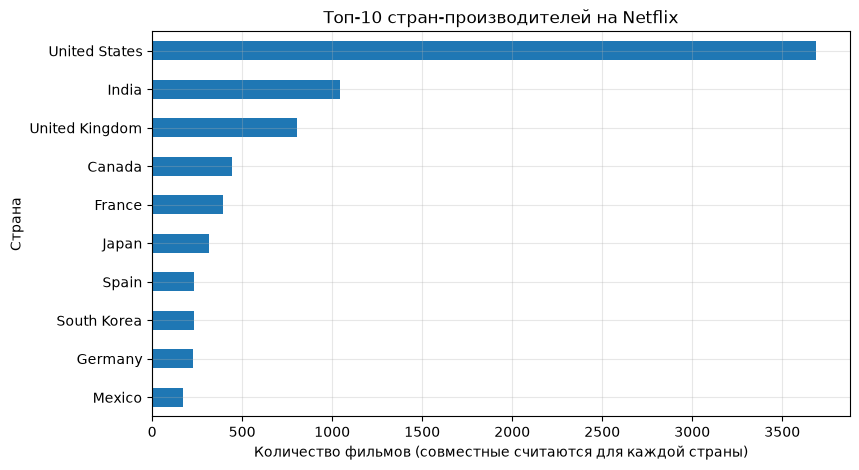

In [31]:
top10.sort_values().plot.barh(color="tab:blue")
plt.title("Топ-10 стран-производителей на Netflix")
plt.xlabel("Количество фильмов (совместные считаются для каждой страны)")
plt.ylabel("Страна")
plt.show()

In [67]:
known = df[df["country"] != "Unknown"].assign( # оставляем известные страны и создаем (ассайним) новый столбец для сша
    has_us=lambda d: d["country"].str.contains("United States")
)
us_by_year = known.groupby("year_added")["has_us"].agg(
    share="mean", # считаем тру(1) фолсы(0) и делим на их количество - получаем долю
    count="count" # считаем где есть us
)
us_by_year = us_by_year[us_by_year["count"] >= MIN_TITLES] # убираем лишние для статистики года
us_by_year["share"] = (us_by_year["share"] * 100).round(1) # и долю в проценты
us_by_year

,share,count
year_added,,
2014,91.7,24
2015,72.2,79
2016,49.5,410
2017,41.1,1123
2018,39.2,1530
2019,46.1,1858
2020,46.8,1771
2021,55.0,1140


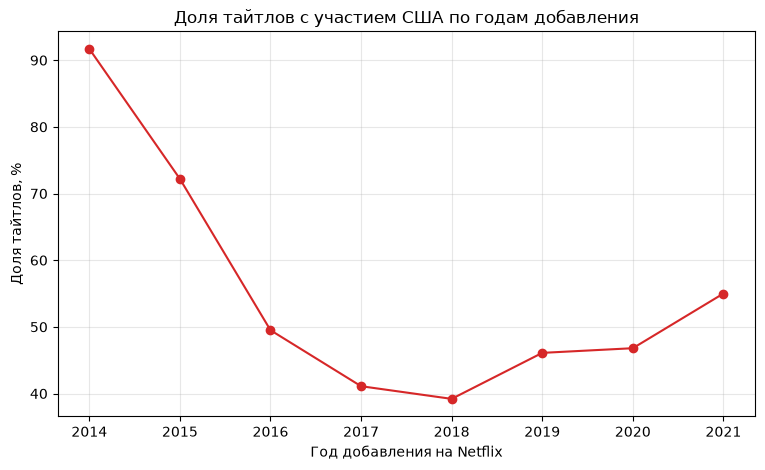

In [68]:
plt.plot(
    us_by_year.index.astype(int),
    us_by_year["share"],
    marker="o", # о ставит круглую точку, * поставит например звездочку
    color="tab:red"
)
plt.title("Доля тайтлов с участием США по годам добавления")
plt.xlabel("Год добавления на Netflix")
plt.ylabel("Доля тайтлов, %")
plt.show()

> Больше всего контента из США (3690 тайтлов), потом Индия (1046) и Великобритания (806). Доля тайтлов с участием США сначала сильно упала (с 72% в 2015 до 39% в 2018), а потом снова выросла до 55% в 2021.

### 3.7 Вопрос 5. Чем отличается жанровый профиль контента из Индии, Японии и Южной Кореи?
Разбиваем и страны, и жанры (`listed_in`) через `explode`, потом строим `pivot_table` с долями.

In [76]:
focus = ["India", "Japan", "South Korea"]

genre_country = analysis.explode_column(
    analysis.explode_column(df, "country"), # сначала страны по колонкам
    "listed_in" # затем и жанры по колонкам (с запятыми тяжко работать)
)
genre_country = genre_country[
    genre_country["country"].isin(focus)
]

counts = genre_country.pivot_table(
    index="listed_in", # строки это жанры
    columns="country", # столбцы это страны
    values="show_id",  # считаем колво фильмов/сериалов (точнее их id) 
    aggfunc="nunique", # на всякий случай уникальные айдишники берем (мало ли после explode появились дубликаты)
    fill_value=0       # пропуски берем за 0
)
titles_per_country = genre_country.groupby("country")["show_id"].nunique()
print("Тайтлов по странам:", titles_per_country.to_dict())

shares = counts.div(titles_per_country, axis=1).mul(100).round(1)
top_genres = shares.max(axis=1).sort_values(ascending=False).head(10).index
shares.loc[top_genres]

Тайтлов по странам: {'India': 1046, 'Japan': 318, 'South Korea': 231}


country,India,Japan,South Korea
listed_in,,,
International Movies,82.6,22.6,19.0
International TV Shows,6.3,47.5,65.8
Dramas,63.3,7.2,11.3
Korean TV Shows,0.0,0.0,57.1
Anime Series,0.0,45.0,0.0
Romantic TV Shows,1.1,6.6,33.3
Comedies,30.9,2.8,7.4
Anime Features,0.0,19.2,0.0
Action & Adventure,13.1,17.9,7.4


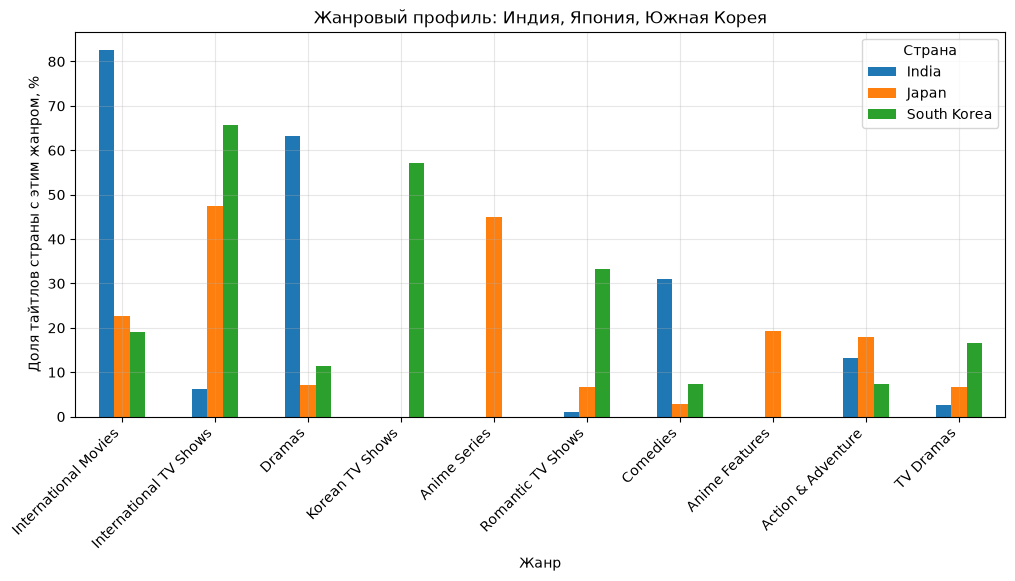

In [77]:
shares.loc[top_genres].plot.bar(figsize=(12, 5))
plt.title("Жанровый профиль: Индия, Япония, Южная Корея")
plt.xlabel("Жанр")
plt.ylabel("Доля тайтлов страны с этим жанром, %")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Страна")
plt.show()

> Три страны делают очень разный контент. Индия — в основном фильмы: драмы и комедии. Южная Корея — в основном сериалы, особенно дорамы и романтика. Япония — аниме (сериалы и полнометражное).

### 3.8 Вопрос 6. В какие месяцы Netflix чаще всего добавляет контент?

In [79]:
months = (
    df.groupby("month_added")
    .size() # что-то вроде каунтера
)
months_table = pd.DataFrame({
    "тайтлов": months.to_numpy(),
    "доля, %": (months / months.sum() * 100).round(1).to_numpy(),
}, index=MONTHS_RU)
months_table

,тайтлов,"доля, %"
Янв,738,8.4
Фев,563,6.4
Мар,742,8.4
Апр,764,8.7
Май,632,7.2
Июн,728,8.3
Июл,827,9.4
Авг,755,8.6
Сен,770,8.8
Окт,760,8.6


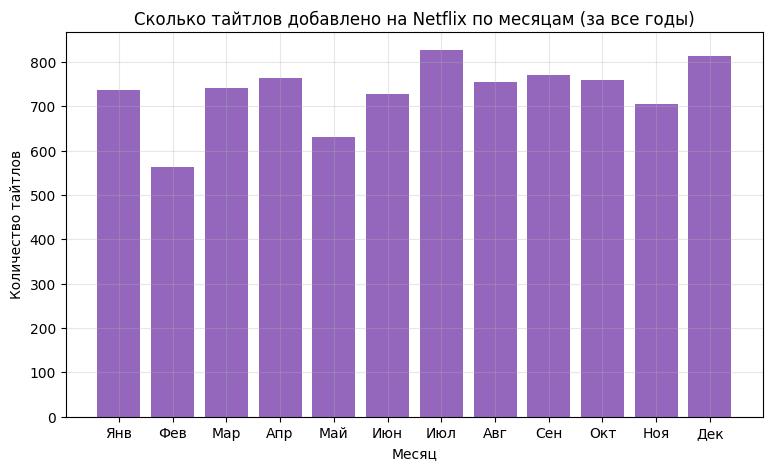

Пик: Июл | минимум: Фев


In [37]:
plt.bar(MONTHS_RU, months_table["тайтлов"], color="tab:purple")
plt.title("Сколько тайтлов добавлено на Netflix по месяцам (за все годы)")
plt.xlabel("Месяц")
plt.ylabel("Количество тайтлов")
plt.show()

print("Пик:", months_table["тайтлов"].idxmax(), "| минимум:", months_table["тайтлов"].idxmin())

> Контент добавляют почти равномерно весь год: от 6.4% (февраль) до 9.4% (июль). Чаще всего в июле и декабре, реже всего в феврале. Резкой сезонности нет - хотя график как будто хочет сказать обратное.

## 4. Главные выводы
**Данные.** В датасете 8807 тайтлов: 6131 фильм и 2676 сериалов. Больше всего пропусков в режиссёрах (30%), в странах и актёрах (по 9%). Все почищено для комфортного анализа.

**Возраст контента.** Netflix добавляет в основном свежее: обычно проходит 1 год между выходом и появлением в каталоге. Старше 10 лет только 14% тайтлов.

**Фильмы и сериалы.** Фильмов примерно две трети. Контента стало намного больше: с 82 тайтлов в 2015 году до 2016 в 2019-м (это пик).

**Длительность.** Фильмы становятся чуть короче: около −6 минут за 10 лет. Сейчас типичный фильм идёт около 95 минут.

**География и жанры.** Больше всего контента из США, потом Индия и Великобритания. Доля США сначала падала (до 39% в 2018), потом выросла до 55% в 2021. Индия делает в основном кино, Корея сериалы (дорамы), Япония аниме.

**Сезонность.** Почти нет: контент добавляют равномерно, чуть чаще в июле и декабре, реже в феврале.

**Ограничения.** Данные заканчиваются в 3 квартале 2021. У 9.4% тайтлов страна неизвестна. date_added это дата добавления в каталог, а не дата выхода.

In [105]:
last_quarter = df["date_added"].max().quarter
unknown_country = df["country"].eq("Unknown").mean() * 100

print(f"Квартал последней даты добавления: {last_quarter}")
print(f"Тайтлов с неизвестной страной: {unknown_country:.1f}%")

Квартал последней даты добавления: 3
Тайтлов с неизвестной страной: 9.4%
